# Voting Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md).
Every lab is **self-contained**: a short goal, the code, the picture/numbers, and a
**"How to read this"** box that tells you what you should notice.

**How to use it**

1. Run the first code cell (imports), then the "two datasets" cell. After that you can run any lab in order
   (`Shift + Enter` cell by cell), or `Kernel → Restart & Run All`. Labs only reuse data from *earlier* cells,
   so running top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output — try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

| Part | Labs | What it proves |
|---|---|---|
| **A. How voting works** | 1 – 4 | Hard / soft / weighted votes and mean / median by hand; Condorcet's jury theorem; why correlated voters stop helping; how scikit-learn does it (ties, `classes_`, `probability=True`) |
| **B. Why it is useful** | 5 – 9 | Three models that are wrong in *different* places → the vote beats all three; diversity measured; hard vs soft; median for regression; weights chosen by cross-validation |
| **C. Where it fails** | 10 – 14 | One good model outvoted by two that fail together (and how weights / stacking fix it); an over-confident member wrecks soft voting; copies give no gain; the cost; a tuned single model may already be enough |

Labs 2 and 3 use two real datasets (Titanic and House Prices). Run `python fetch_datasets.py` once in this folder
to fetch them from OpenML (internet needed once); they are saved as CSV files in `openml_data/`, which git ignores.
`datasets_and_members.py` cleans them and builds the members, so the notebook itself only shows voting. All the other data
is generated in the notebook (and saved to `data/`) or comes from scikit-learn's built-in generators.

In [2]:
import time
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.stats import binom
import sklearn

from sklearn.calibration import CalibratedClassifierCV
from sklearn.datasets import make_moons
from sklearn.ensemble import StackingClassifier, VotingClassifier, VotingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeRegressor

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

REGION_CMAP = ListedColormap(["#c6dbef", "#fcbba1"])   # light blue = class 0, light red = class 1
POINT_CMAP = ListedColormap(["#2166ac", "#b2182b"])    # dark blue = class 0, dark red = class 1


def make_members(k=25):
    """The three members used throughout: a straight-line model, naive Bayes and k-nearest-neighbours."""
    return [("lr", make_pipeline(StandardScaler(), LogisticRegression())),
            ("nb", GaussianNB()),
            ("knn", KNeighborsClassifier(n_neighbors=k))]


def plot_regions(ax, model, X, y, title, X_show=None, y_show=None):
    """Colour the plane by the model's prediction; draw (X_show, y_show) on top; mark mistakes with a black x."""
    X_show = X if X_show is None else X_show
    y_show = y if y_show is None else y_show
    x1 = np.linspace(X[:, 0].min() - 0.7, X[:, 0].max() + 0.7, 300)
    x2 = np.linspace(X[:, 1].min() - 0.7, X[:, 1].max() + 0.7, 220)
    grid = np.column_stack([g.ravel() for g in np.meshgrid(x1, x2)])
    ax.contourf(x1, x2, model.predict(grid).reshape(len(x2), len(x1)), levels=[-0.5, 0.5, 1.5], cmap=REGION_CMAP)
    ax.scatter(X_show[:, 0], X_show[:, 1], c=y_show, cmap=POINT_CMAP, s=9, vmin=0, vmax=1)
    wrong = model.predict(X_show) != y_show
    ax.scatter(X_show[wrong, 0], X_show[wrong, 1], marker="x", c="k", s=30, linewidths=1.2)
    ax.set_title(f"{title}\naccuracy {np.mean(~wrong):.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

---
# The two datasets

Both live on a 2-D map (two features, `x1` and `x2`) so every model can be drawn. They are generated here,
saved to `data/good_fit.csv` and `data/bad_fit.csv` (columns `x1,x2,y`), and re-used by the from-scratch notebook.

**Good fit — "three kinds of trouble on one map"** (README §1, §7). Eleven little Gaussian groups of points:

* **Centre and two wings — a straight but tilted boundary.** Class 1 (red) sits *above* a tilted line: low on the
  left wing (x1 ≈ −6), high on the right wing (x1 ≈ +6). Both classes have exactly the same left/right split, so
  `x1` *on its own* says nothing about the class — only the combination "where are you left-right **and** how high"
  does. Naive Bayes looks at each feature on its own, so this part is built to trip **naive Bayes**.
* **The cap — a boundary that bends back.** A strip of class 0 (blue) floats *above* everything at x2 ≈ 3.5. So
  class 0 lives at the bottom **and** at the top, class 1 in a band between. No single straight line can do that:
  built to trip **logistic regression**.
* **Four tiny groups — a "clustered" part.** Four groups of only 7 class-1 points each, just under the cap.
  With k = 25 neighbours, a group of 7 is always outvoted by the cap: built to trip **k-NN**.

**Bad fit — "only one member can do it"** (README §8.1). Four blobs in an XOR pattern: class 1 in the top-right and
(a smaller one in) the bottom-left, class 0 in the other two corners. Only k-NN can draw an XOR; logistic regression
and naive Bayes both fail on the *same* corner, so they outvote k-NN there.

good_fit.csv: 26 kB
bad_fit.csv: 20 kB
good fit: (1328, 2) class counts [700 628]
bad fit : (1050, 2) class counts [600 450]


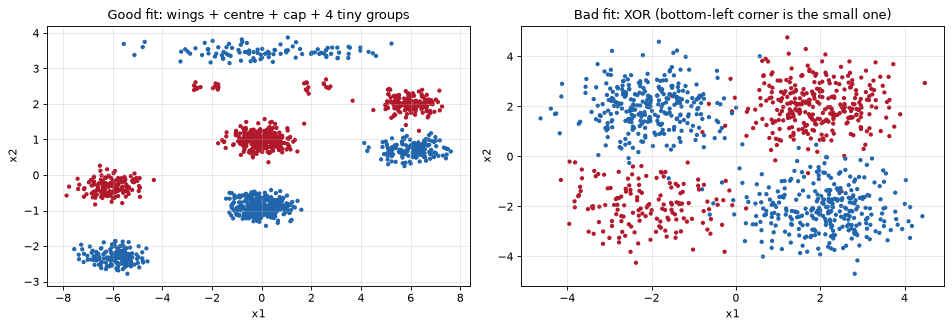

In [3]:
DATA = Path("data")
DATA.mkdir(exist_ok=True)

GOOD_GROUPS = [  # (centre, spread (sd in x1, x2), number of points, class)
    ((-6.0, -0.35), (0.6, 0.2), 150, 1),   # 0 left wing, upper   (class 1)
    ((6.0, 2.0),    (0.6, 0.2), 150, 1),   # 1 right wing, upper  (class 1)
    ((0.0, 1.0),    (0.6, 0.2), 300, 1),   # 2 centre, upper      (class 1)
    ((-2.6, 2.5),   (0.1, 0.07), 7, 1),    # 3-6 four tiny groups under the cap (class 1)
    ((-1.8, 2.5),   (0.1, 0.07), 7, 1),
    ((1.8, 2.5),    (0.1, 0.07), 7, 1),
    ((2.6, 2.5),    (0.1, 0.07), 7, 1),
    ((-6.0, -2.3),  (0.6, 0.2), 150, 0),   # 7 left wing, lower   (class 0)
    ((6.0, 0.75),   (0.6, 0.2), 150, 0),   # 8 right wing, lower  (class 0)
    ((0.0, -0.9),   (0.6, 0.2), 300, 0),   # 9 centre, lower      (class 0)
    ((0.0, 3.5),    (2.4, 0.15), 100, 0),  # 10 the cap on top    (class 0)
]
GROUP_NAMES = ["L-wing up", "R-wing up", "centre up", "tiny", "tiny", "tiny", "tiny",
               "L-wing low", "R-wing low", "centre low", "cap"]


def make_good_fit(seed=0):
    """Good-fit map: returns X (n, 2), y (n,) and the group id of every point; saves data/good_fit.csv."""
    rng = np.random.default_rng(seed)
    X = np.vstack([rng.normal(c, s, size=(n, 2)) for c, s, n, _ in GOOD_GROUPS])
    y = np.concatenate([np.full(n, label) for _, _, n, label in GOOD_GROUPS])
    group = np.concatenate([np.full(n, g) for g, (_, _, n, _) in enumerate(GOOD_GROUPS)])
    np.savetxt(DATA / "good_fit.csv", np.column_stack([X, y]), delimiter=",", header="x1,x2,y", comments="", fmt="%.6g")
    return X, y, group


def make_bad_fit(seed=0):
    """Bad-fit XOR: class 1 top-right (300) and bottom-left (150), class 0 top-left and bottom-right (300 each)."""
    rng = np.random.default_rng(seed)
    centres, sizes, labels = [(2, 2), (-2, 2), (2, -2), (-2, -2)], [300, 300, 300, 150], [1, 0, 0, 1]
    X = np.vstack([rng.normal(c, 0.9, size=(n, 2)) for c, n in zip(centres, sizes)])
    y = np.concatenate([np.full(n, label) for n, label in zip(sizes, labels)])
    corner = np.concatenate([np.full(n, j) for j, n in enumerate(sizes)])
    np.savetxt(DATA / "bad_fit.csv", np.column_stack([X, y]), delimiter=",", header="x1,x2,y", comments="", fmt="%.6g")
    return X, y, corner


X_good, y_good, g_good = make_good_fit(seed=0)
X_bad, y_bad, c_bad = make_bad_fit(seed=0)
for name in ["good_fit.csv", "bad_fit.csv"]:
    print(f"{name}: {(DATA / name).stat().st_size / 1e3:.0f} kB")
print("good fit:", X_good.shape, "class counts", np.bincount(y_good))
print("bad fit :", X_bad.shape, "class counts", np.bincount(y_bad))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, X, y, title in [(axes[0], X_good, y_good, "Good fit: wings + centre + cap + 4 tiny groups"),
                        (axes[1], X_bad, y_bad, "Bad fit: XOR (bottom-left corner is the small one)")]:
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=POINT_CMAP, s=8)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.tight_layout(); plt.show()

---
# Part A — How voting works

## Lab 1 · The hand-worked example, done by the computer

**Goal:** reproduce README §5 number by number: three classifiers A, B, C give a probability of "class 1" for five
samples → their own predictions → hard vote, soft vote, weighted hard vote (with a tie) → and the regression part
(mean, median, weighted mean with one broken member).

own predictions (rows A, B, C):
 [[1 1 0 1 1]
 [1 0 0 1 0]
 [0 0 1 0 1]]
accuracy of A, B, C: [0.4 0.4 0.8]

votes for class 1 : [2 1 1 2 2] -> hard vote [1 0 0 1 1]  accuracy 0.6
average P(class 1): [0.667 0.4   0.6   0.417 0.55 ] -> soft vote [1 0 1 0 1]  accuracy 1.0
  s1: weight for class 0 = 1, for class 1 = 3 -> 1
  s2: weight for class 0 = 2, for class 1 = 2 -> 0   (tie -> first class in `classes`)
  s3: weight for class 0 = 3, for class 1 = 1 -> 0
  s4: weight for class 0 = 1, for class 1 = 3 -> 1
  s5: weight for class 0 = 1, for class 1 = 3 -> 1
weighted hard vote (2,1,1): [1 0 0 1 1]  accuracy 0.6


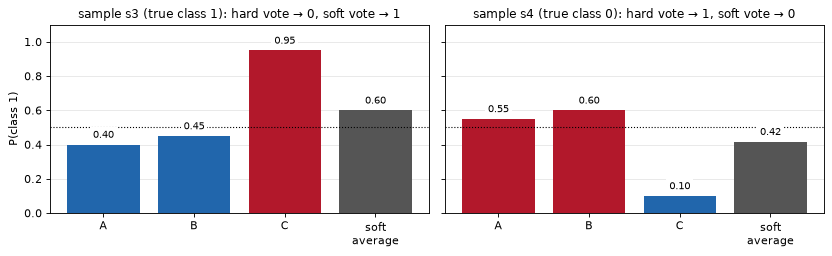

In [4]:
y_true = np.array([1, 0, 1, 0, 1])
p_class1 = np.array([[0.90, 0.60, 0.40, 0.55, 0.70],    # classifier A: P(class 1) for samples s1..s5
                     [0.80, 0.40, 0.45, 0.60, 0.30],    # classifier B
                     [0.30, 0.20, 0.95, 0.10, 0.65]])   # classifier C
classes = np.array([0, 1])

labels = (p_class1 > 0.5).astype(int)                   # each classifier's own prediction
print("own predictions (rows A, B, C):\n", labels)
print("accuracy of A, B, C:", (labels == y_true).mean(axis=1))

votes_for_1 = labels.sum(axis=0)                        # hard vote = the most common label (the mode)
hard = (votes_for_1 >= 2).astype(int)
print("\nvotes for class 1 :", votes_for_1, "-> hard vote", hard, " accuracy", (hard == y_true).mean())

soft_p1 = p_class1.mean(axis=0)                         # soft vote = average the probabilities, then pick the larger
soft = (soft_p1 > 0.5).astype(int)
print("average P(class 1):", soft_p1, "-> soft vote", soft, " accuracy", (soft == y_true).mean())

w = np.array([2, 1, 1])                                 # weighted hard vote: A's vote counts twice
weighted = []
for j in range(5):
    tally = np.bincount(labels[:, j], weights=w, minlength=2)   # [weight voting 0, weight voting 1]
    weighted.append(classes[np.argmax(tally)])                  # np.argmax returns the FIRST maximum -> ties go to class 0
    print(f"  s{j + 1}: weight for class 0 = {tally[0]:.0f}, for class 1 = {tally[1]:.0f} -> {weighted[-1]}"
          + ("   (tie -> first class in `classes`)" if tally[0] == tally[1] else ""))
print("weighted hard vote (2,1,1):", np.array(weighted), " accuracy", (np.array(weighted) == y_true).mean())

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3), sharey=True)
for ax, j in zip(axes, [2, 3]):                          # s3 and s4: the samples where hard and soft vote disagree
    heights = list(p_class1[:, j]) + [soft_p1[j]]
    colours = [POINT_CMAP(int(p > 0.5)) for p in p_class1[:, j]] + ["#555555"]   # bar colour = the member's own class
    ax.bar(["A", "B", "C", "soft\naverage"], heights, color=colours)
    for x, h in enumerate(heights):
        ax.text(x, h + 0.025, f"{h:.2f}", ha="center", va="bottom", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=2.5))
    ax.axhline(0.5, color="k", ls=":", lw=1)
    ax.set_ylim(0, 1.1); ax.set_axisbelow(True); ax.grid(axis="x", visible=False)   # grid behind the bars
    ax.set_title(f"sample s{j + 1} (true class {y_true[j]}): hard vote → {hard[j]}, soft vote → {soft[j]}", fontsize=11)
axes[0].set_ylabel("P(class 1)")
plt.tight_layout()
fig.savefig("../images/hard_vs_soft_hand_example.png", dpi=100, bbox_inches="tight")   # README section 3.2
plt.show()

In [5]:
y_reg = np.array([10.0, 20.0, 15.0])
reg_preds = np.array([[11.0, 19.0, 14.0],     # regressor R1
                      [9.0, 22.0, 15.0],      # regressor R2
                      [30.0, 60.0, 40.0]])    # regressor R3 - broken (way too high)
mean_pred = reg_preds.mean(axis=0)
median_pred = np.median(reg_preds, axis=0)
wmean_pred = np.average(reg_preds, axis=0, weights=[2, 2, 1])
for name, pred in [("R1", reg_preds[0]), ("R2", reg_preds[1]), ("R3", reg_preds[2]),
                   ("mean", mean_pred), ("median", median_pred), ("weighted mean (2,2,1)", wmean_pred)]:
    print(f"{name:22s} predictions {np.round(pred, 2)}   mean absolute error {mean_absolute_error(y_reg, pred):.2f}")
print("mode: every value appears once ->", "no mode (each of the three numbers is different on every sample)")

R1                     predictions [11. 19. 14.]   mean absolute error 1.00
R2                     predictions [ 9. 22. 15.]   mean absolute error 1.00
R3                     predictions [30. 60. 40.]   mean absolute error 28.33
mean                   predictions [16.67 33.67 23.  ]   mean absolute error 9.44
median                 predictions [11. 22. 15.]   mean absolute error 1.00
weighted mean (2,2,1)  predictions [14.  28.4 19.6]   mean absolute error 5.67
mode: every value appears once -> no mode (each of the three numbers is different on every sample)


> **How to read this**
> * A, B and C are each right on 2, 2 and 4 of the 5 samples (accuracy 0.4, 0.4, 0.8).
> * **Hard vote** = count the labels. It goes wrong on s3 (A and B say 0, only C says 1) and s4 (A and B say 1):
>   accuracy **0.6 — worse than C alone**. Two weak members that agree beat the one strong member.
> * **Soft vote** averages the probabilities: s3 gets (0.40 + 0.45 + 0.95)/3 = 0.60 → class 1, s4 gets 0.417 →
>   class 0. C was *very* sure on both and A, B were only *slightly* sure, so C wins: accuracy **1.0**.
> * **Weighted hard vote (2, 1, 1)**: on s2, A (weight 2) says 1 and B + C (weight 1 + 1) say 0 → a 2 : 2 **tie**.
>   `np.argmax` returns the first maximum, so the tie goes to class 0 — exactly scikit-learn's rule (Lab 4).
> * **Regression**: the broken R3 drags the **mean** to 16.67, 33.67, 23.0 (error 9.44); the **median** ignores it
>   (11, 22, 15; error 1.00); the weighted mean (2, 2, 1) is in between (error 5.67). With three different numbers
>   there is no "most common" value — the mode is useless for regression.

## Lab 2 · Condorcet's jury theorem with real members: how close do they get?

**Goal:** README §4.2. The theorem says that voters who are **independent** and each better than a coin give a majority that improves as voters are added. Models trained on the same data are never independent. Five real models vote on the Titanic passengers: how much of the theorem's promise do they keep?

**Data:** the Titanic passenger list from OpenML (1,309 passengers, the same size as Kaggle's training and test files together). Run `python fetch_datasets.py` once in this folder to fetch it into `openml_data/` (git ignores that folder); `datasets_and_members.py` then cleans it, so this notebook stays about voting. Features: class, sex, age, siblings/spouses, parents/children, fare and port of embarkation. `boat` and `body` are left out: a lifeboat number means "survived" and a body number means "died", so they would hand every model the answer. Every prediction is **out-of-fold**: each passenger is predicted by a copy of the model that never saw that passenger. Model settings were fixed in advance and nothing was tuned.

In [6]:
import itertools

import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict

# Cleaning and the members live in datasets_and_members.py; run `python fetch_datasets.py` once (in this folder) to fetch the data.
from datasets_and_members import house_members, load_house_prices, load_titanic, titanic_members

X_ti, y_ti = load_titanic()          # 1,309 passengers: class, sex, age, siblings/spouses, parents/children, fare, port
members_ti = titanic_members()       # softmax regression, decision tree, k-NN, naive Bayes, SVC: settings fixed in advance
names_ti = [name for name, _ in members_ti]

# Each passenger is predicted by a copy of the member that never saw that passenger (5-fold cross-validation).
folds_ti = StratifiedKFold(5, shuffle=True, random_state=0)
labels_ti = np.array([cross_val_predict(model, X_ti, y_ti, cv=folds_ti) for _, model in members_ti])   # shape (5, 1309)
wrong_ti = (labels_ti != y_ti).astype(float)                                                            # 1 where the member is wrong
acc_ti = 1 - wrong_ti.mean(axis=1)

print(f"{len(y_ti)} passengers, {y_ti.mean():.1%} survived  ->  always answering 'died' is right {1 - y_ti.mean():.1%} of the time")
for name, a in zip(names_ti, acc_ti):
    print(f"  {name:8s} accuracy {a:.3f}")


1309 passengers, 38.2% survived  ->  always answering 'died' is right 61.8% of the time
  softmax  accuracy 0.785
  tree     accuracy 0.791
  knn      accuracy 0.791
  nb       accuracy 0.778
  svc      accuracy 0.807


In [18]:
tp_arr = np.array([1.0])
print(tp_arr)

tp_arr = np.convolve(tp_arr, [1-0.8, 0.8])
print(tp_arr)

tp_arr = np.convolve(tp_arr, [1-0.7, 0.7])
print(tp_arr)

tp_arr = np.convolve(tp_arr, [1-0.65, 0.65])
print(tp_arr)

print(tp_arr[3 // 2 + 1:].sum())


[1.]
[0.2 0.8]
[0.06 0.38 0.56]
[0.021 0.172 0.443 0.364]
0.8069999999999999


`np.convolve(a: (M,), b: (N,))`: $$(a * v)[k] = \sum_{m} a[m] \cdot v[k - m]$$

- Step1: [1.0] * [0.2, 0.8] $\rightarrow$ [1.0 * 0.2, 1.0 * 0.8] = `[0.2, 0.8]`
- Step2: [0.2, 0.8] * [0.3, 0.7] $\rightarrow$ [0.2 * 0.3 (k=0), 0.2 * 0.7 + 0.8 * 0.3 = **0.38** (k=1) ,  0 + 0.8 * 0.7 + 0 = **0.56** (k=2)] = [0.06, 0.38, 0.56] = `[0.06, 0.38, 0.56]`
- Step2: [0.06, 0.38, 0.56] * [0.35, 0.65] $\rightarrow$ [0.06 * 0.35 = **0.021** (k=0), 0.06 * 0.65 + 0.38 * 0.35 = **0.172** (k=1) ,  0.06\*0 + 0.38\*0.65 + 0.56\*0.35 = **0.443** (k=2), 0 + 0 + 0.56 * 0.65 = **0.364** (k=3)] = `[0.021, 0.172, 0.443, 0.364]`


for the return line: `return right[len(p) // 2 + 1:].sum()` got evaluated to `0.443 + 0.364 = 0.806999`

members                     actual  if independent    gap  best member
softmax+tree+knn             0.795           0.886  0.090        0.791
softmax+tree+nb              0.788           0.881  0.094        0.791
softmax+tree+svc             0.804           0.891  0.086        0.807
softmax+knn+nb               0.784           0.881  0.098        0.791
softmax+knn+svc              0.799           0.891  0.092        0.807
softmax+nb+svc               0.788           0.887  0.098        0.807
tree+knn+nb                  0.794           0.883  0.089        0.791
tree+knn+svc                 0.808           0.893  0.084        0.807
tree+nb+svc                  0.807           0.889  0.082        0.807
knn+nb+svc                   0.796           0.889  0.093        0.807
softmax+tree+knn+nb+svc      0.800           0.935  0.135        0.807

committees of 3 that beat their own best member: 3 of 10 (equal: 1, worse: 6); the vote of all 5 vs its best member: 0.800 vs 0.807

VotingClassifi

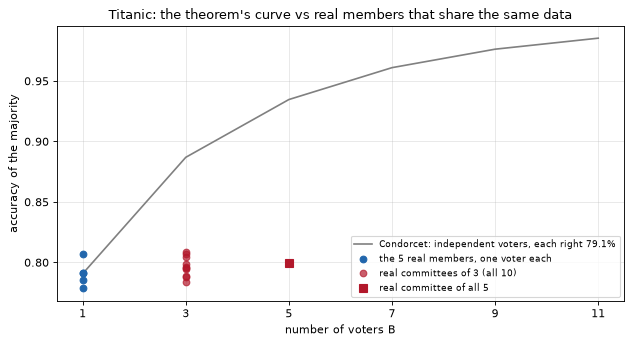

In [ ]:
def independent_majority(p):
    """Condorcet for voters with different accuracies p[i]: P(more than half are right) IF they were independent."""
    right = np.array([1.0])                              # right[k] = P(exactly k voters right so far)
    for p_i in p:
        right = np.convolve(right, [1 - p_i, p_i])
    return right[len(p) // 2 + 1:].sum()


committees = []                                          # every 3 of the 5 members, then all 5
for idx in list(itertools.combinations(range(5), 3)) + [tuple(range(5))]:
    i = list(idx)

    # titatnic being a binary classification, simply summing up can tell how many voted yes and no.
    # and majority voting for yes means more than M/2 estimatirs voted yes,  M: len(i)
    vote = (labels_ti[i].sum(axis=0) > len(i) / 2).astype(int)           # majority of the out-of-fold labels = a hard vote
    pairs = [np.corrcoef(wrong_ti[a], wrong_ti[b])[0, 1] for a, b in itertools.combinations(i, 2)]
    committees.append(dict(members=[names_ti[k] for k in i], actual=(vote == y_ti).mean(),
                           independent=independent_majority(acc_ti[i]), mean_corr=np.mean(pairs), best=acc_ti[i].max()))

print(f"{'members':26s} {'actual':>7s} {'if independent':>15s} {'gap':>6s} {'best member':>12s}")
for c in committees:
    print(f"{'+'.join(c['members']):26s} {c['actual']:7.3f} {c['independent']:15.3f} {c['independent'] - c['actual']:6.3f} {c['best']:12.3f}")

triples = [c for c in committees if len(c["members"]) == 3]
beat = sum(c["actual"] > c["best"] + 1e-9 for c in triples)
tied = sum(abs(c["actual"] - c["best"]) <= 1e-9 for c in triples)
print(f"\ncommittees of 3 that beat their own best member: {beat} of 10 (equal: {tied}, worse: {10 - beat - tied}); "
      f"the vote of all 5 vs its best member: {committees[-1]['actual']:.3f} vs {committees[-1]['best']:.3f}")

# check: scikit-learn's hard VotingClassifier on the same folds gives exactly the majority computed above
vc_labels = cross_val_predict(VotingClassifier(members_ti[:3], voting="hard"), X_ti, y_ti, cv=folds_ti)
print("\nVotingClassifier(hard) = majority of the members' labels:",
      bool((vc_labels == (labels_ti[:3].sum(axis=0) > 1.5).astype(int)).all()))

Bs = np.arange(1, 12, 2)
p_mean = acc_ti.mean()
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(Bs, [binom.sf(B // 2, B, p_mean) for B in Bs], color="gray",
        label=f"Condorcet: independent voters, each right {p_mean:.1%}")
ax.plot(np.ones(5), acc_ti, "o", color="#2166ac", label="the 5 real members, one voter each")
ax.plot(np.full(len(triples), 3), [c["actual"] for c in triples], "o", color="#b2182b", alpha=0.7, label="real committees of 3 (all 10)")
ax.plot([5], [committees[-1]["actual"]], "s", color="#b2182b", ms=8, label="real committee of all 5")
ax.set_xlabel("number of voters B"); ax.set_ylabel("accuracy of the majority")
ax.set_title("Titanic: the theorem's curve vs real members that share the same data")
ax.set_xticks(Bs); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
fig.savefig("../images/real_condorcet_titanic.png", dpi=100, bbox_inches="tight")
plt.show()


In [7]:
print("Is this one lucky split? The same experiment with 10 different cross-validation splits (first 3 members, then all 5):")
for seed in range(10):
    folds = StratifiedKFold(5, shuffle=True, random_state=seed)
    lab = np.array([cross_val_predict(model, X_ti, y_ti, cv=folds) for _, model in members_ti])
    acc = 1 - (lab != y_ti).mean(axis=1)
    line = []
    for i in ([0, 1, 2], [0, 1, 2, 3, 4]):
        vote = (lab[i].sum(axis=0) > len(i) / 2).astype(int)
        line.append(f"{len(i)} members: real {(vote == y_ti).mean():.3f} vs independent {independent_majority(acc[i]):.3f}")
    print(f"  split {seed}: " + " | ".join(line) + f" | best single member {acc.max():.3f}")


Is this one lucky split? The same experiment with 10 different cross-validation splits (first 3 members, then all 5):
  split 0: 3 members: real 0.795 vs independent 0.886 | 5 members: real 0.800 vs independent 0.935 | best single member 0.807


  split 1: 3 members: real 0.791 vs independent 0.887 | 5 members: real 0.798 vs independent 0.935 | best single member 0.804
  split 2: 3 members: real 0.807 vs independent 0.889 | 5 members: real 0.811 vs independent 0.937 | best single member 0.810


  split 3: 3 members: real 0.800 vs independent 0.885 | 5 members: real 0.806 vs independent 0.936 | best single member 0.812
  split 4: 3 members: real 0.801 vs independent 0.884 | 5 members: real 0.800 vs independent 0.934 | best single member 0.806


  split 5: 3 members: real 0.793 vs independent 0.877 | 5 members: real 0.792 vs independent 0.931 | best single member 0.807


  split 6: 3 members: real 0.801 vs independent 0.890 | 5 members: real 0.804 vs independent 0.937 | best single member 0.810
  split 7: 3 members: real 0.794 vs independent 0.888 | 5 members: real 0.798 vs independent 0.936 | best single member 0.808


  split 8: 3 members: real 0.799 vs independent 0.882 | 5 members: real 0.803 vs independent 0.934 | best single member 0.811
  split 9: 3 members: real 0.810 vs independent 0.894 | 5 members: real 0.804 vs independent 0.939 | best single member 0.809


> **How to read this**
> * Five different kinds of model are right 77.8–80.7 % of the time. Answering "died" for everybody would be right 61.8 % of the time.
> * Condorcet's theorem for *independent* voters of that accuracy (grey curve) promises 88–89 % for a majority of 3 and 93.5 % for all 5.
> * The real committees of 3 reach 78.4–80.8 %, and all five together 80.0 %. Only 3 of the 10 committees of 3 beat their own best member, and the vote of all five (0.800) does not beat the best single member (0.807).
> * Not a lucky split: over 10 different cross-validation splits the committees of 3 land at 79.1–81.0 % (independent: 87.7–89.4 %) and all five at 79.2–81.1 % (independent: 93.1–93.9 %). The vote of all five beats the best single member in 1 of the 10 splits.
> * The theorem is not wrong: it is a statement about independent voters, and these members are not independent. They learn from the same passengers and the same seven features, and they tend to make the same mistakes (Lab 3 measures that). The gap between the grey curve and the dots is the price of sharing the data.
> * A caution on size: with 1,309 passengers, half a point of accuracy is about 7 passengers. Differences of a few tenths of a point between committees are noise; the 8 to 13 point gap to the independent curve is not.

## Lab 3 · Correlated errors: why real voters fall short, and when averaging still helps

**Goal:** README §4.3. Measure how strongly real members' errors are correlated: first for the Titanic classifiers of Lab 2, then for a regression problem. \
The regression data are 1,460 houses from Ames, Iowa (OpenML's copy of the data of Kaggle's "House Prices" competition). \
The target is the log of the sale price; the members are a linear regression (plain least squares, no regularisation), a decision tree and k-NN, averaged by `VotingRegressor`. \
Settings were fixed in advance and nothing was tuned; predictions are out-of-fold. The same two scripts fetch and clean this data.

         softmax  tree   knn    nb   svc
softmax     1.00  0.68  0.72  0.83  0.78
tree        0.68  1.00  0.69  0.62  0.79
knn         0.72  0.69  1.00  0.72  0.80
nb          0.83  0.62  0.72  1.00  0.74
svc         0.78  0.79  0.80  0.74  1.00
pairwise error correlation: min 0.62, mean 0.74, max 0.83
the 10 committees of 3: shortfall vs Condorcet 0.082 to 0.098; correlation between a committee's mean error correlation and its shortfall: 0.34


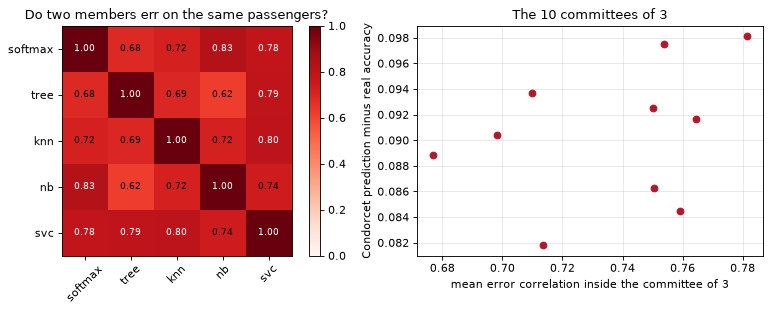

In [8]:
corr_ti = np.corrcoef(wrong_ti)          # correlation between "member i is wrong" and "member j is wrong", over the 1,309 passengers
print(pd.DataFrame(corr_ti, index=names_ti, columns=names_ti).round(2).to_string())
off_diagonal = corr_ti[np.triu_indices(5, 1)]
print(f"pairwise error correlation: min {off_diagonal.min():.2f}, mean {off_diagonal.mean():.2f}, max {off_diagonal.max():.2f}")

gap = np.array([c["independent"] - c["actual"] for c in triples])
rho = np.array([c["mean_corr"] for c in triples])
print(f"the 10 committees of 3: shortfall vs Condorcet {gap.min():.3f} to {gap.max():.3f}; "
      f"correlation between a committee's mean error correlation and its shortfall: {np.corrcoef(rho, gap)[0, 1]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
im = axes[0].imshow(corr_ti, vmin=0, vmax=1, cmap="Reds")
axes[0].set_xticks(range(5)); axes[0].set_xticklabels(names_ti, rotation=45)
axes[0].set_yticks(range(5)); axes[0].set_yticklabels(names_ti)
for a in range(5):
    for b in range(5):
        axes[0].text(b, a, f"{corr_ti[a, b]:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if corr_ti[a, b] > 0.75 else "black")
axes[0].set_title("Do two members err on the same passengers?"); axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].plot(rho, gap, "o", color="#b2182b")
axes[1].set_xlabel("mean error correlation inside the committee of 3")
axes[1].set_ylabel("Condorcet prediction minus real accuracy")
axes[1].set_title("The 10 committees of 3")
plt.tight_layout()
fig.savefig("../images/real_error_correlation.png", dpi=100, bbox_inches="tight")
plt.show()


> **How to read this (Titanic)**
> * For two members, the correlation between "wrong on this passenger" is 0.62–0.83 (mean 0.74). Where one member is wrong the others usually are too, so a majority has few mistakes to outvote.
> * The 10 committees of 3 differ little in their mean error correlation (0.68–0.78) and in their shortfall against Condorcet (8.2–9.8 points). The two are only weakly related (r = 0.34 over 10 points that share members, so not a reliable estimate): all the committees sit in the same high-correlation region.

1460 houses, 79 features (36 numeric, 43 categorical); spread of the target (std of log price) 0.399
  linear  RMSE 0.1795
  tree    RMSE 0.1946
  knn     RMSE 0.1746

error correlation:
         linear  tree   knn
linear    1.00  0.39  0.47
tree      0.39  1.00  0.54
knn       0.47  0.54  1.00

average of            real RMSE  if errors were uncorrelated  best member
linear+tree              0.1558                       0.1324       0.1795
linear+knn               0.1516                       0.1252       0.1746
tree+knn                 0.1619                       0.1307       0.1746
linear+tree+knn          0.1465                       0.1057       0.1746



VotingRegressor = mean of the members' predictions: True


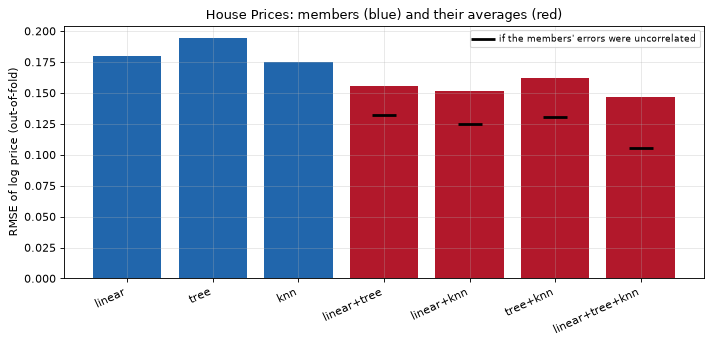

In [9]:
# Regression: 1,460 houses from Ames, Iowa (the data of Kaggle's "House Prices" competition). Target: log of the sale price.
X_h, y_h = load_house_prices()
members_h = house_members(X_h)       # linear regression (plain least squares), decision tree, k-NN: settings fixed in advance
names_h = [name for name, _ in members_h]
folds_h = KFold(5, shuffle=True, random_state=0)
pred_h = np.array([cross_val_predict(model, X_h, y_h, cv=folds_h) for _, model in members_h])      # out-of-fold predictions, (3, 1460)
err_h = y_h - pred_h
mse_h = (err_h ** 2).mean(axis=1)
n_numeric = X_h.select_dtypes(include="number").shape[1]
print(f"{len(y_h)} houses, {X_h.shape[1]} features ({n_numeric} numeric, {X_h.shape[1] - n_numeric} categorical); "
      f"spread of the target (std of log price) {y_h.std():.3f}")
for name, m in zip(names_h, mse_h):
    print(f"  {name:7s} RMSE {np.sqrt(m):.4f}")
print("\nerror correlation:\n", pd.DataFrame(np.corrcoef(err_h), index=names_h, columns=names_h).round(2).to_string())

print(f"\n{'average of':20s} {'real RMSE':>10s} {'if errors were uncorrelated':>28s} {'best member':>12s}")
combos = [(0, 1), (0, 2), (1, 2), (0, 1, 2)]
real, ideal = [], []
for idx in combos:
    i = list(idx)
    real.append(np.sqrt(((y_h - pred_h[i].mean(axis=0)) ** 2).mean()))
    ideal.append(np.sqrt(mse_h[i].sum() / len(i) ** 2))          # MSE of an average of B uncorrelated errors = (sum of MSEs) / B^2
    print(f"{'+'.join(names_h[k] for k in i):20s} {real[-1]:10.4f} {ideal[-1]:28.4f} {np.sqrt(mse_h[i]).min():12.4f}")
vr_pred = cross_val_predict(VotingRegressor(members_h), X_h, y_h, cv=folds_h)
print("\nVotingRegressor = mean of the members' predictions:", bool(np.allclose(vr_pred, pred_h.mean(axis=0))))

labels_bar = names_h + ["+".join(names_h[k] for k in c) for c in combos]
fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(labels_bar))
ax.bar(x, list(np.sqrt(mse_h)) + real, color=["#2166ac"] * 3 + ["#b2182b"] * 4)
ax.plot(x[3:], ideal, "k_", ms=22, mew=2.5, label="if the members' errors were uncorrelated")
ax.set_xticks(x); ax.set_xticklabels(labels_bar, rotation=25, ha="right")
ax.set_ylabel("RMSE of log price (out-of-fold)"); ax.legend(fontsize=8)
ax.set_title("House Prices: members (blue) and their averages (red)")
plt.tight_layout()
fig.savefig("../images/real_house_prices_average.png", dpi=100, bbox_inches="tight")
plt.show()


> **How to read this (House Prices)**
> * The members' errors are less correlated here (0.39–0.54), and averaging pays: the average of all three has RMSE 0.1465 (log price), 16 % below the best member (0.1746). Every pair's average also beats both of its members.
> * It still falls short of the 0.1057 that uncorrelated errors would give (the red bars sit above the black dashes). The leftover is the part of the errors the members share.
> * Compared with Titanic, a lower error correlation (about 0.47 here, 0.74 there) goes with a clear gain from combining, and a high one with almost none. That is the README's point about correlation. But these are two different problems (a vote on labels, an average of numbers), so this lab alone does not prove it.

## Lab 4 · How scikit-learn does it: fitted members, `classes_`, tie-breaking, `probability=True`

**Goal:** README §6. Look inside a fitted `VotingClassifier`, prove which class wins a tie in a hard vote, and see why
a plain `SVC` cannot take part in a soft vote.

In [10]:
X_tr, X_te, y_tr, y_te = train_test_split(X_good, y_good, test_size=0.3, random_state=0, stratify=y_good)
vote_w = VotingClassifier(make_members(), voting="hard", weights=[1, 1, 2]).fit(X_tr, y_tr)   # k-NN counts twice
print("classes_:", vote_w.classes_)
print("fitted members:", [type(est).__name__ for est in vote_w.estimators_])

member_labels = vote_w.transform(X_te)                 # hard voting: one column of predicted labels per member
weight_for_1 = member_labels @ np.array([1, 1, 2])     # total weight voting for class 1 (the rest votes for 0)
ties = weight_for_1 == 2                               # 2 of the 4 weight units on each side
print(f"test points: {len(y_te)}, ties (LR + NB against k-NN): {ties.sum()}")
print("what VotingClassifier predicted on the ties:", np.unique(vote_w.predict(X_te[ties]), return_counts=True))

# The same with text labels: classes_ is sorted alphabetically, so "cat" (first) wins every tie.
pets = np.where(y_tr == 1, "dog", "cat")
vote_pets = VotingClassifier(make_members(), voting="hard", weights=[1, 1, 2]).fit(X_tr, pets)
print("\ntext labels -> classes_:", vote_pets.classes_, "| ties predicted as:",
      np.unique(vote_pets.predict(X_te[ties]), return_counts=True))

classes_: [0 1]
fitted members: ['Pipeline', 'GaussianNB', 'KNeighborsClassifier']
test points: 399, ties (LR + NB against k-NN): 7
what VotingClassifier predicted on the ties: (array([0]), array([7]))

text labels -> classes_: ['cat' 'dog'] | ties predicted as: (array(['cat'], dtype='<U3'), array([7]))


In [11]:
moons_X, moons_y = make_moons(400, noise=0.3, random_state=0)
print("plain SVC has predict_proba?", hasattr(SVC().fit(moons_X, moons_y), "predict_proba"))
try:
    VotingClassifier([("lr", LogisticRegression()), ("svc", SVC())], voting="soft").fit(moons_X, moons_y).predict(moons_X)
except AttributeError as err:
    print("soft vote with a plain SVC ->", type(err).__name__, ":", err)

with warnings.catch_warnings(record=True) as caught:        # the old switch still works but is deprecated in 1.9
    warnings.simplefilter("always")
    SVC(probability=True, random_state=0).fit(moons_X, moons_y)
print(f"\nSVC(probability=True) in scikit-learn {sklearn.__version__}:", caught[0].category.__name__)
print("  ", str(caught[0].message))

svc_cal = CalibratedClassifierCV(SVC(), ensemble=False)       # the recommended way: calibrate the SVM scores with 5-fold CV
soft_svc = VotingClassifier([("lr", LogisticRegression()), ("svc", svc_cal)], voting="soft").fit(moons_X, moons_y)
print("\nsoft vote of LR + calibrated SVC works, training accuracy:", round(soft_svc.score(moons_X, moons_y), 3))
svc_plain = SVC().fit(moons_X, moons_y)
svc_cal_fit = soft_svc.named_estimators_["svc"]
print("points where plain SVC.predict() and the calibrated SVC's argmax(predict_proba) disagree:",
      int((svc_plain.predict(moons_X) != svc_cal_fit.predict_proba(moons_X).argmax(axis=1)).sum()), "of", len(moons_y))

plain SVC has predict_proba? False
soft vote with a plain SVC -> AttributeError : This 'SVC' has no attribute 'predict_proba'

SVC(probability=True) in scikit-learn 1.9.1: FutureWarning
   The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`

soft vote of LR + calibrated SVC works, training accuracy: 0.895
points where plain SVC.predict() and the calibrated SVC's argmax(predict_proba) disagree: 0 of 400


> **How to read this**
> * `estimators_` holds the three **fitted** members; `classes_` is the sorted list of labels. With weights (1, 1, 2)
>   a tie happens whenever logistic regression and naive Bayes (1 + 1) disagree with k-NN (2). All of these ties came
>   out as class 0, the **first entry of `classes_`** — scikit-learn computes `argmax(bincount(votes, weights))`,
>   and `argmax` returns the first maximum. With text labels the first class is the alphabetically first one
>   (`"cat"`): the tie-break depends on how your labels are spelled, not on anything meaningful.
> * A plain `SVC` has no `predict_proba` (it only knows which side of its boundary a point is on, and how far), so
>   the soft vote crashes. The classic switch `SVC(probability=True)` adds one by fitting a logistic curve to the SVM
>   scores with an internal 5-fold cross-validation — it still works, but scikit-learn 1.9 deprecates it (warning
>   caught and printed above) in favour of `CalibratedClassifierCV(SVC(), ensemble=False)`, which does the same job.
> * Either way the probabilities come from a *second* model fitted on top of the SVM. Here its argmax agrees with the
>   plain SVM on all 400 points, but that is not guaranteed — the two are separate fits.

---
# Part B — Why voting is useful

## Lab 5 · The good-fit map: three members, three different blind spots, one vote that beats them all

**Goal:** README §1, §3, §7. Train the three members and both kinds of vote on the good-fit data, draw what each one
predicts everywhere on the map, and count mistakes group by group.

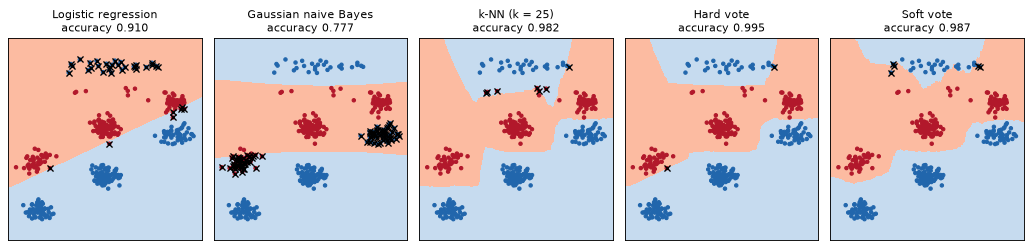

test accuracy     L-wing up L-wing low  R-wing up R-wing low  centre up centre low       tiny        cap     ALL
(test points)            44         53         49         48         89         80          7         29     399
lr                     0.98       1.00       0.90       1.00       0.99       1.00       1.00       0.00   0.910
nb                     0.07       1.00       1.00       0.00       1.00       1.00       1.00       1.00   0.777
knn                    1.00       1.00       1.00       1.00       1.00       1.00       0.14       0.97   0.982
hard vote              0.98       1.00       1.00       1.00       1.00       1.00       1.00       0.97   0.995
soft vote              1.00       1.00       1.00       1.00       1.00       1.00       1.00       0.83   0.987


In [12]:
members = make_members()
models = {name: est.fit(X_tr, y_tr) for name, est in members}
models["hard vote"] = VotingClassifier(make_members(), voting="hard").fit(X_tr, y_tr)
models["soft vote"] = VotingClassifier(make_members(), voting="soft").fit(X_tr, y_tr)
titles = {"lr": "Logistic regression", "nb": "Gaussian naive Bayes", "knn": "k-NN (k = 25)",
          "hard vote": "Hard vote", "soft vote": "Soft vote"}

fig, axes = plt.subplots(1, 5, figsize=(13, 3.2))
for ax, (name, model) in zip(axes, models.items()):
    plot_regions(ax, model, X_good, y_good, titles[name], X_te, y_te)
plt.tight_layout()
fig.savefig("../images/good_fit_members_vs_vote.png", dpi=100, bbox_inches="tight")   # README section 1
plt.show()

_, g_te = train_test_split(g_good, test_size=0.3, random_state=0, stratify=y_good)
group_kind = np.array(GROUP_NAMES)[g_te]
kinds = ["L-wing up", "L-wing low", "R-wing up", "R-wing low", "centre up", "centre low", "tiny", "cap"]
print(f"{'test accuracy':16s}" + "".join(f"{k:>11s}" for k in kinds) + f"{'ALL':>8s}")
print(f"{'(test points)':16s}" + "".join(f"{(group_kind == k).sum():>11d}" for k in kinds) + f"{len(y_te):>8d}")
for name, model in models.items():
    right = model.predict(X_te) == y_te
    print(f"{name:16s}" + "".join(f"{right[group_kind == k].mean():>11.2f}" for k in kinds) + f"{right.mean():>8.3f}")

> **How to read this** (crosses = test points that model gets wrong)
> * **Logistic regression** draws one tilted straight line. It gets both wings and the centre right, but the cap
>   (class 0 *above* class 1) is on the wrong side of any line: 0.00 on the cap (accuracy 0.910 overall).
> * **Naive Bayes** builds one bell curve per class and per feature. Class 0 is spread out vertically (bottom *and*
>   cap), class 1 is narrow, so it predicts "class 1 in a horizontal band" — which handles the cap. But `x1` alone
>   carries no class information here, so its band cannot tilt: it misses the low class-1 wing on the left (0.07) and
>   the high class-0 wing on the right (0.00) — 0.777 overall.
> * **k-NN** follows every curve, but each tiny group has only ~5 training points and k = 25: the cap outvotes them
>   (0.14 on the 7 tiny-group test points; 0.982 overall).
> * Each member is wrong in **its own** place, and in each place the other two are right → the **hard vote** fixes
>   all three blind spots: **0.995**, better than every member. The **soft vote** (0.987) also beats every member
>   here, but it loses some cap points (0.83): logistic regression is *very* sure (probability ≈ 0.9 for the wrong
>   class) far from its line, and that confidence can outweigh the other two (more in Lab 7).

## Lab 6 · Diversity, measured: who is wrong where?

**Goal:** README §4.4. Voting can only fix a mistake if the *other* members get that point right. Count, for every
test point, how many members are wrong, and measure how strongly the members' mistakes go together.

GOOD FIT
  points wrong by exactly 0 / 1 / 2 / 3 members: [269 128   2   0]
  correlation of mistakes (rows/cols = lr, nb, knn):
 [[ 1.   -0.15  0.02]
 [-0.15  1.   -0.07]
 [ 0.02 -0.07  1.  ]]

BAD FIT
  points wrong by exactly 0 / 1 / 2 / 3 members: [237  16  58   4]
  correlation of mistakes (rows/cols = lr, nb, knn):
 [[1.   0.86 0.18]
 [0.86 1.   0.13]
 [0.18 0.13 1.  ]]


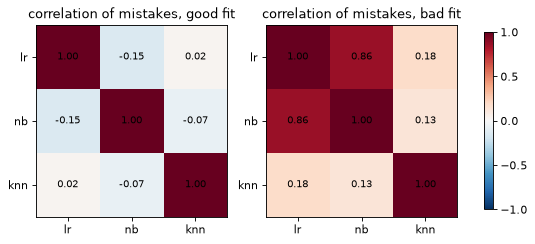

In [13]:
def error_profile(models_dict, X, y, title):
    wrong = np.array([m.predict(X) != y for m in models_dict.values()])     # rows = members
    n_wrong = wrong.sum(axis=0)
    print(title)
    print("  points wrong by exactly 0 / 1 / 2 / 3 members:", np.bincount(n_wrong, minlength=4))
    corr = np.corrcoef(wrong.astype(float))
    print("  correlation of mistakes (rows/cols = lr, nb, knn):\n", np.round(corr, 2))
    return corr


corr_good = error_profile({k: models[k] for k in ["lr", "nb", "knn"]}, X_te, y_te, "GOOD FIT")
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_bad, y_bad, test_size=0.3, random_state=0, stratify=y_bad)
models_bad = {name: est.fit(Xb_tr, yb_tr) for name, est in make_members()}
corr_bad = error_profile(models_bad, Xb_te, yb_te, "\nBAD FIT")

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
for ax, corr, title in [(axes[0], corr_good, "good fit"), (axes[1], corr_bad, "bad fit")]:
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(3)); ax.set_xticklabels(["lr", "nb", "knn"]); ax.set_yticks(range(3)); ax.set_yticklabels(["lr", "nb", "knn"])
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(f"correlation of mistakes, {title}"); ax.grid(False)
plt.colorbar(im, ax=axes, shrink=0.8); plt.show()

> **How to read this**
> * Good fit: 128 test points are missed by exactly **one** member, only 2 by two and none by all three — so almost
>   always a right majority exists. The mistake correlations are about zero or slightly **negative** (−0.15, 0.02,
>   −0.07: when one member is wrong, the others tend to be right) — the ideal situation for voting.
> * Bad fit: logistic regression and naive Bayes are wrong on the **same** points (correlation of their mistakes
>   0.86), so 58 points are missed by two members at once (and 4 by all three). On those points the vote is wrong
>   even though k-NN is usually right — Lab 10 shows the damage.
> * Diversity is not "the members are different algorithms"; it is "their **mistakes** are different". Check it like
>   this before trusting a vote.

## Lab 7 · Hard vs soft voting: when averaging probabilities helps, and when it hurts

**Goal:** README §3, §4.5. On noisy two-moons data, soft voting uses *how sure* each member is and beats hard voting.
On the good-fit map it does slightly worse, because one member is confidently wrong on the cap.

two moons (noise 0.3):
  lr   0.840
  nb   0.843
  knn  0.913
  hard 0.843   soft 0.880
  hard and soft disagree on 13 points; soft is right on 12 of them

good fit, cap points (true class 0): average P(class 1) given by lr, nb, knn: [0.92 0.22 0.2 ]
  soft average > 0.5 (soft vote wrong) on 5 of 29 cap test points
  hard vote wrong on 1 of them


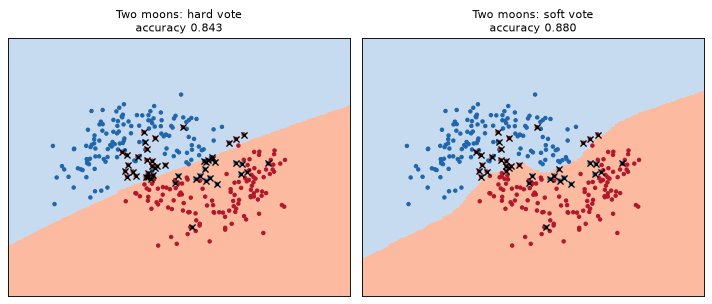

In [14]:
Xm, ym = make_moons(1000, noise=0.3, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=0, stratify=ym)
print("two moons (noise 0.3):")
for name, est in make_members():
    print(f"  {name:4s} {est.fit(Xm_tr, ym_tr).score(Xm_te, ym_te):.3f}")
hard_m = VotingClassifier(make_members(), voting="hard").fit(Xm_tr, ym_tr)
soft_m = VotingClassifier(make_members(), voting="soft").fit(Xm_tr, ym_tr)
print(f"  hard {hard_m.score(Xm_te, ym_te):.3f}   soft {soft_m.score(Xm_te, ym_te):.3f}")
disagree = hard_m.predict(Xm_te) != soft_m.predict(Xm_te)
print(f"  hard and soft disagree on {disagree.sum()} points; soft is right on {np.sum(soft_m.predict(Xm_te)[disagree] == ym_te[disagree])} of them")

cap_te = group_kind == "cap"
proba_cap = np.array([models[k].predict_proba(X_te[cap_te])[:, 1] for k in ["lr", "nb", "knn"]])
print("\ngood fit, cap points (true class 0): average P(class 1) given by lr, nb, knn:", proba_cap.mean(axis=1).round(2))
print("  soft average > 0.5 (soft vote wrong) on", int((proba_cap.mean(axis=0) > 0.5).sum()), "of", cap_te.sum(), "cap test points")
print("  hard vote wrong on", int((models["hard vote"].predict(X_te[cap_te]) != 0).sum()), "of them")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
plot_regions(axes[0], hard_m, Xm, ym, "Two moons: hard vote", Xm_te, ym_te)
plot_regions(axes[1], soft_m, Xm, ym, "Two moons: soft vote", Xm_te, ym_te)
plt.tight_layout(); plt.show()

> **How to read this**
> * On the moons every member is unsure near the overlap. Hard voting throws that away (a 51 % "yes" counts as much
>   as a 99 % "yes"); soft voting keeps it: 0.880 vs 0.843. On the 13 points where the two votes disagree, soft is
>   right 12 times. (k-NN alone, 0.913, is still better here — on smooth 2-D data with lots of points it is hard to
>   beat.)
> * On the good-fit cap, logistic regression says "class 1" with probability ≈ 0.9 while naive Bayes and k-NN say
>   "class 1" with only ≈ 0.2 each — the average lands just above or below 0.5 point by point, so the soft vote gets
>   5 of the 29 cap test points wrong where the hard vote (which only counts 1 against 2) misses 1.
> * Rule of thumb: **soft** when the members' probabilities are honest (calibrated); **hard** when one member can be
>   confidently wrong. Lab 11 shows the extreme case.

## Lab 8 · Regression: mean vs median when one member goes wild

**Goal:** README §3.4, §5. `VotingRegressor` averages (mean). A degree-15 polynomial fitted to 50 points is fine in the
middle but swings wildly near the edges of the data; see how the mean and the median cope.

knn                      mean absolute error 0.313   worst error    0.83
tree                     mean absolute error 0.430   worst error    1.22
poly15                   mean absolute error 2.362   worst error   46.65
mean (VotingRegressor)   mean absolute error 0.965   worst error   15.18
median                   mean absolute error 0.314   worst error    0.94

weights chosen by 5-fold CV on the training set: [1, 1, 0] -> test error 0.363


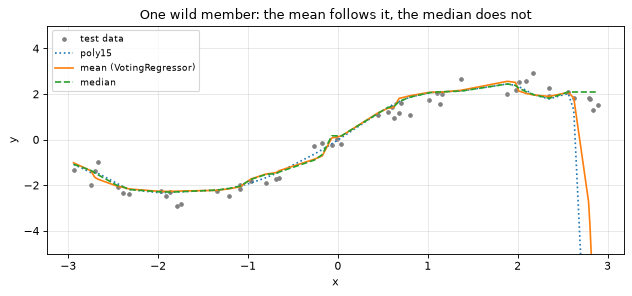

In [15]:
rng = np.random.default_rng(2)                                   # <- try changing this (the wild swings depend on it)
x_reg = rng.uniform(-3, 3, 100)
y_reg_all = 2 * np.sin(x_reg) + 0.3 * x_reg + rng.normal(0, 0.3, 100)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(x_reg[:, None], y_reg_all, test_size=0.5, random_state=0)

regressors = [("knn", KNeighborsRegressor(n_neighbors=5)),
              ("tree", DecisionTreeRegressor(max_depth=4, random_state=0)),
              ("poly15", make_pipeline(StandardScaler(), PolynomialFeatures(15), LinearRegression()))]
reg_out = {name: est.fit(Xr_tr, yr_tr).predict(Xr_te) for name, est in regressors}
vote_mean = VotingRegressor(regressors).fit(Xr_tr, yr_tr)
reg_out["mean (VotingRegressor)"] = vote_mean.predict(Xr_te)
reg_out["median"] = np.median(np.array([reg_out[n] for n, _ in regressors]), axis=0)
for name, pred in reg_out.items():
    print(f"{name:24s} mean absolute error {mean_absolute_error(yr_te, pred):.3f}   worst error {np.abs(pred - yr_te).max():7.2f}")

search_w = GridSearchCV(VotingRegressor(regressors), {"weights": [[1, 1, 1], [1, 1, 0], [1, 0, 1], [0, 1, 1], [2, 1, 1], [1, 2, 1]]},
                        cv=5, scoring="neg_mean_absolute_error").fit(Xr_tr, yr_tr)
print("\nweights chosen by 5-fold CV on the training set:", search_w.best_params_["weights"],
      f"-> test error {mean_absolute_error(yr_te, search_w.predict(Xr_te)):.3f}")

order = np.argsort(Xr_te[:, 0])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(Xr_te[:, 0], yr_te, s=10, c="gray", label="test data")
for name, style in [("poly15", ":"), ("mean (VotingRegressor)", "-"), ("median", "--")]:
    ax.plot(Xr_te[order, 0], reg_out[name][order], style, label=name)
ax.set_ylim(-5, 5); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=8)
ax.set_title("One wild member: the mean follows it, the median does not")
plt.tight_layout(); plt.show()

> **How to read this**
> * The polynomial is fine in the middle but wild near the edges: mean absolute error 2.36, worst single error 46.7.
> * The **mean** (what `VotingRegressor` does) is dragged along: error 0.965, worst 15.2 — a third of a huge error is
>   still a big error.
> * The **median** of three numbers is the middle one, so a single wild member is simply ignored: error 0.314, as
>   good as the best member (k-NN, 0.313).
> * Weights chosen by cross-validation *on the training set only* find a similar cure from the data: weights
>   (1, 1, 0), i.e. drop the polynomial (test error 0.363).

## Lab 9 · Choosing weights by cross-validation (never on the test set)

**Goal:** README §6.3. Try every weight vector in a small grid with 5-fold cross-validation **inside the training set**,
keep the best, and touch the test set once.

In [16]:
grid = {"weights": [[a, b, c] for a in (1, 2, 3) for b in (1, 2, 3) for c in (1, 2, 3)]}
search = GridSearchCV(VotingClassifier(make_members(), voting="hard"), grid, cv=5).fit(X_tr, y_tr)
ranked = sorted(zip(search.cv_results_["mean_test_score"], map(tuple, search.cv_results_["param_weights"])), key=lambda t: -t[0])
print("best 5 weight vectors by CV accuracy (training set only):")
for score, wts in ranked[:5]:
    print(f"  weights {wts}: CV accuracy {score:.4f}")
print("weight vectors tied for the best CV accuracy:", sum(sc == ranked[0][0] for sc, _ in ranked), "of", len(ranked))
print(f"\ntest accuracy, chosen weights {search.best_params_['weights']}: {search.score(X_te, y_te):.3f}"
      f"   vs equal weights: {models['hard vote'].score(X_te, y_te):.3f}")

best 5 weight vectors by CV accuracy (training set only):
  weights (1, 1, 1): CV accuracy 0.9935
  weights (1, 2, 2): CV accuracy 0.9935
  weights (1, 3, 3): CV accuracy 0.9935
  weights (2, 1, 2): CV accuracy 0.9935
  weights (2, 2, 1): CV accuracy 0.9935
weight vectors tied for the best CV accuracy: 15 of 27

test accuracy, chosen weights [1, 1, 1]: 0.995   vs equal weights: 0.995


> **How to read this**
> * On the good-fit map equal weights are already (among) the best: every member is the expert somewhere, so no one
>   should be silenced. Several weight vectors tie; CV just keeps the first best one.
> * The important part is the **procedure**: the 27 candidates were compared with cross-validation on the training
>   data, and the test set was used once at the end. Choosing weights by looking at test accuracy would make that
>   test number optimistic (leakage).
> * Lab 10 shows a dataset where the weights matter a lot.

---
# Part C — Where voting fails

## Lab 10 · Bad fit: one member can solve it, the other two fail together

**Goal:** README §8.1. On the XOR data only k-NN is right in the small bottom-left corner. Logistic regression and naive
Bayes are wrong there *together*, so the majority overrules k-NN. Then two fixes: weights chosen by CV, and
**stacking** (a small model that *learns* how much to trust each member, from out-of-fold predictions).

test accuracy       top-right (1)      top-left (0)  bottom-right (0)   bottom-left (1)     ALL
lr                           0.88              0.84              1.00              0.00   0.784
nb                           0.94              0.78              1.00              0.00   0.781
knn                          0.96              1.00              0.97              0.98   0.978
hard vote                    0.93              0.86              1.00              0.00   0.803
soft vote                    0.96              1.00              0.99              0.56   0.927
weighted (CV)                0.96              1.00              0.97              0.98   0.978
stacking                     0.96              1.00              0.97              0.98   0.978

weights chosen by CV: [1, 1, 3]
stacking: weight the final logistic regression gives to each member's P(class 1) (lr, nb, knn): [[0.31 0.3  7.07]]


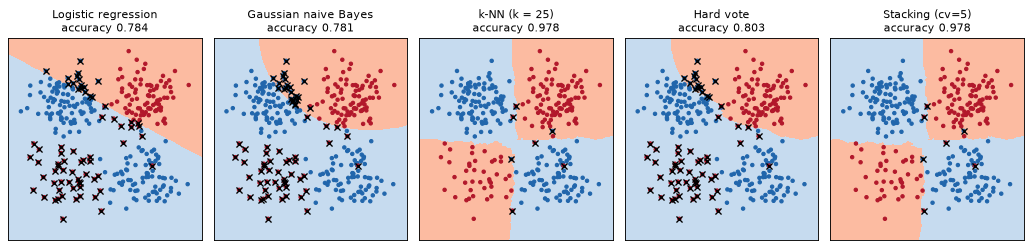

In [17]:
bad_models = {name: est.fit(Xb_tr, yb_tr) for name, est in make_members()}
bad_models["hard vote"] = VotingClassifier(make_members(), voting="hard").fit(Xb_tr, yb_tr)
bad_models["soft vote"] = VotingClassifier(make_members(), voting="soft").fit(Xb_tr, yb_tr)
search_bad = GridSearchCV(VotingClassifier(make_members(), voting="hard"), grid, cv=5).fit(Xb_tr, yb_tr)
bad_models["weighted (CV)"] = search_bad.best_estimator_
bad_models["stacking"] = StackingClassifier(make_members(), final_estimator=LogisticRegression(), cv=5).fit(Xb_tr, yb_tr)

_, cb_te = train_test_split(c_bad, test_size=0.3, random_state=0, stratify=y_bad)
corner_names = ["top-right (1)", "top-left (0)", "bottom-right (0)", "bottom-left (1)"]
print(f"{'test accuracy':15s}" + "".join(f"{c:>18s}" for c in corner_names) + f"{'ALL':>8s}")
for name, model in bad_models.items():
    right = model.predict(Xb_te) == yb_te
    print(f"{name:15s}" + "".join(f"{right[cb_te == j].mean():>18.2f}" for j in range(4)) + f"{right.mean():>8.3f}")
print("\nweights chosen by CV:", search_bad.best_params_["weights"])
print("stacking: weight the final logistic regression gives to each member's P(class 1) (lr, nb, knn):",
      bad_models["stacking"].final_estimator_.coef_.round(2))

fig, axes = plt.subplots(1, 5, figsize=(13, 3.2))
for ax, name in zip(axes, ["lr", "nb", "knn", "hard vote", "stacking"]):
    plot_regions(ax, bad_models[name], X_bad, y_bad, titles.get(name, "Stacking (cv=5)"), Xb_te, yb_te)
plt.tight_layout()
fig.savefig("../images/bad_fit_outvoted.png", dpi=100, bbox_inches="tight")   # README section 8.1
plt.show()

> **How to read this**
> * Logistic regression and naive Bayes both cut off the top-right blob and call the whole bottom-left corner class 0
>   (0.00 there for both). k-NN gets every corner right (0.96–1.00).
> * The **hard vote** copies the two that agree: 0.803, barely better than they are (0.784, 0.781) and far worse than
>   k-NN alone (0.978). This is Condorcet's assumption breaking: the members are not independent, and on that corner
>   two of them are certain to be wrong.
> * The **soft vote** recovers part of the corner (0.56 there, 0.927 overall) — LR and NB are unsure there while
>   k-NN is sure — but not all of it.
> * **Weights chosen by CV** — (1, 1, 3): k-NN's vote now outweighs the other two together — and **stacking** both
>   get back to 0.978. Stacking learned a weight of 7.07 for k-NN's probability and only 0.31 / 0.30 for the
>   others. It was trained on **out-of-fold** predictions (`cv=5`): each member's prediction for a training point
>   came from a copy of that member that had *not* seen the point (the from-scratch notebook shows what goes wrong
>   otherwise).
> * Honest conclusion: here the best "ensemble" is essentially k-NN alone. Voting only pays off when the members are
>   comparably good **and** wrong in different places.

## Lab 11 · An over-confident member breaks soft voting

**Goal:** README §4.5, §8.4. Add eight noisy copies of feature `x1` to the moons data. Naive Bayes assumes the features
are independent, so it counts the same evidence nine times and becomes absurdly sure of itself. Soft voting then
listens mostly to naive Bayes. Fix: calibrate it (`CalibratedClassifierCV`).

lr   accuracy 0.840
nb   accuracy 0.737
knn  accuracy 0.910
naive Bayes is more than 99 % sure on 82% of test points, but right on only 74% of them

hard vote 0.850 | soft vote 0.833 | soft vote with calibrated NB 0.880
the plain soft vote agrees with naive Bayes on 90% of test points


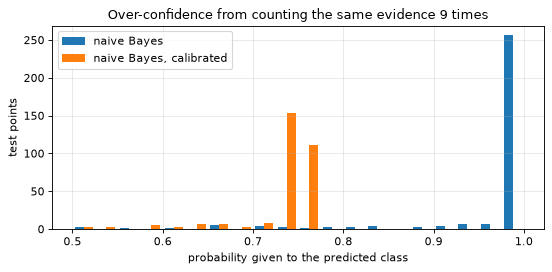

In [18]:
rng = np.random.default_rng(0)
X2, yc = make_moons(1000, noise=0.3, random_state=0)
Xc = np.hstack([X2, X2[:, [0]] + rng.normal(0, 0.15, size=(len(yc), 8))])   # 2 real features + 8 noisy copies of x1
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.3, random_state=0, stratify=yc)
copy_members = [("lr", make_pipeline(StandardScaler(), LogisticRegression())),
                ("nb", GaussianNB()),
                ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)))]
for name, est in copy_members:
    print(f"{name:4s} accuracy {est.fit(Xc_tr, yc_tr).score(Xc_te, yc_te):.3f}")
nb_conf = copy_members[1][1].predict_proba(Xc_te).max(axis=1)
print(f"naive Bayes is more than 99 % sure on {np.mean(nb_conf > 0.99):.0%} of test points, but right on only "
      f"{copy_members[1][1].score(Xc_te, yc_te):.0%} of them")
hard_c = VotingClassifier(copy_members, voting="hard").fit(Xc_tr, yc_tr)
soft_c = VotingClassifier(copy_members, voting="soft").fit(Xc_tr, yc_tr)
calib_members = [copy_members[0], ("nb", CalibratedClassifierCV(GaussianNB(), cv=5)), copy_members[2]]
soft_cal = VotingClassifier(calib_members, voting="soft").fit(Xc_tr, yc_tr)
print(f"\nhard vote {hard_c.score(Xc_te, yc_te):.3f} | soft vote {soft_c.score(Xc_te, yc_te):.3f}"
      f" | soft vote with calibrated NB {soft_cal.score(Xc_te, yc_te):.3f}")
follows_nb = soft_c.predict(Xc_te) == copy_members[1][1].predict(Xc_te)
print(f"the plain soft vote agrees with naive Bayes on {follows_nb.mean():.0%} of test points")

fig, ax = plt.subplots(figsize=(7, 3.5))
cal_conf = soft_cal.named_estimators_["nb"].predict_proba(Xc_te).max(axis=1)
ax.hist([nb_conf, cal_conf], bins=np.linspace(0.5, 1, 21), label=["naive Bayes", "naive Bayes, calibrated"])
ax.set_xlabel("probability given to the predicted class"); ax.set_ylabel("test points"); ax.legend()
ax.set_title("Over-confidence from counting the same evidence 9 times")
plt.tight_layout(); plt.show()

> **How to read this**
> * Naive Bayes is the weakest member, yet it is more than 99 % sure on most points. In a soft vote a 0.999 can
>   outweigh two members saying 0.3, so the soft vote largely copies naive Bayes and ends **below** the hard vote.
> * Hard voting ignores confidence, so it is not fooled.
> * Calibration (here `CalibratedClassifierCV`, which re-maps naive Bayes' scores with cross-validation) makes its
>   probabilities honest again (orange bars: mostly around 0.75, matching its real hit rate, instead of piled at
>   1.0), and the soft vote recovers to 0.880.
> * Soft voting assumes the members' probabilities are on the **same, honest scale**. Check calibration first.

## Lab 12 · Copies are not a committee

**Goal:** README §4.3, §8.3. Three k-NN models with k = 25, 31, 37 are three "different" models that make almost the
same mistakes. Vote them and nothing improves.

In [19]:
copies = [(f"knn{k}", KNeighborsClassifier(n_neighbors=k)) for k in (25, 31, 37)]
copy_models = {name: est.fit(X_tr, y_tr) for name, est in copies}
for name, model in copy_models.items():
    print(f"{name:6s} accuracy {model.score(X_te, y_te):.3f}")
vote_copies = VotingClassifier(copies, voting="hard").fit(X_tr, y_tr)
print(f"hard vote of the three k-NNs: {vote_copies.score(X_te, y_te):.3f}")
wrong = np.array([m.predict(X_te) != y_te for m in copy_models.values()])
print("points wrong by 0 / 1 / 2 / 3 members:", np.bincount(wrong.sum(axis=0), minlength=4))
print("correlation of mistakes:\n", np.round(np.corrcoef(wrong.astype(float)), 2))

knn25  accuracy 0.982
knn31  accuracy 0.980
knn37  accuracy 0.975
hard vote of the three k-NNs: 0.980
points wrong by 0 / 1 / 2 / 3 members: [389   2   1   7]
correlation of mistakes:
 [[1.   0.93 0.83]
 [0.93 1.   0.89]
 [0.83 0.89 1.  ]]


> **How to read this**
> * The three copies miss the same tiny-group and cap points: 7 points are missed by all three, only 3 by one or two,
>   and the mistake correlations are 0.83–0.93. So the vote (0.980) is no better than a single copy (0.975–0.982).
> * Compare with Lab 5, where three *different kinds* of model reached a much higher accuracy. Same number of
>   members, completely different outcome: what counts is how different the **mistakes** are.

## Lab 13 · The bill: B models to train, store and run

**Goal:** README §8.6–8.7. A vote of B models costs (at least) the sum of their costs, and there is no single
formula to read off. Time fitting and predicting on a 100× bigger copy of the good-fit map.

In [20]:
big = [make_good_fit(seed=s) for s in range(1, 101)]       # 100 fresh copies of the map
X_big, y_big = np.vstack([b[0] for b in big]), np.concatenate([b[1] for b in big])
make_good_fit(seed=0)                                    # re-save the seed-0 CSV (the loop above overwrote it)
print("big data:", X_big.shape)


def time_it(model):
    t0 = time.perf_counter(); model.fit(X_big, y_big); t1 = time.perf_counter()
    model.predict(X_big); t2 = time.perf_counter()
    return t1 - t0, t2 - t1


for name, est in make_members() + [("hard vote", VotingClassifier(make_members(), voting="hard"))]:
    fit_s, pred_s = time_it(est)
    print(f"{name:10s} fit {fit_s * 1000:8.1f} ms   predict {pred_s * 1000:8.1f} ms")
print("\nlogistic regression can be read off as one line:", models["lr"][-1].coef_.round(2), models["lr"][-1].intercept_.round(2),
      "(on scaled features)")
print("the vote has no coefficients of its own - only three different models to explain.")

big data: (132800, 2)


lr         fit     14.2 ms   predict      1.4 ms
nb         fit      6.1 ms   predict      3.6 ms


knn        fit     18.6 ms   predict    247.4 ms


hard vote  fit     41.3 ms   predict    402.1 ms

logistic regression can be read off as one line: [[-0.78  1.39]] [-0.08] (on scaled features)
the vote has no coefficients of its own - only three different models to explain.


> **How to read this**
> * The vote's fit and predict times are (roughly) the sum of its members' — here dominated by k-NN, whose
>   prediction has to search the training set. With B members you store and serve B models.
> * Logistic regression alone can be explained with three numbers; the vote cannot be summarised that way. If a
>   decision must be explained (credit, medicine), that matters.
> * These numbers vary from machine to machine; the *ratio* is the point.

## Lab 14 · A well-tuned single model can make the vote unnecessary

**Goal:** README §8.8. Every lab so far used k = 25 for k-NN (close to the rule of thumb k ≈ √n_train ≈ 30). Choose
k by 5-fold cross-validation on the training set instead, and compare that single tuned model with the vote.

In [21]:
tuned_knn = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": list(range(1, 40, 2))}, cv=5).fit(X_tr, y_tr)
print("k chosen by CV:", tuned_knn.best_params_["n_neighbors"], f"(CV accuracy {tuned_knn.best_score_:.4f})")
print(f"tuned k-NN alone, test accuracy: {tuned_knn.score(X_te, y_te):.3f}")
print(f"hard vote with k = 25          : {models['hard vote'].score(X_te, y_te):.3f}")
tuned_vote = VotingClassifier(make_members(k=tuned_knn.best_params_["n_neighbors"]), voting="hard").fit(X_tr, y_tr)
print(f"hard vote with the tuned k     : {tuned_vote.score(X_te, y_te):.3f}")

k chosen by CV: 1 (CV accuracy 0.9989)
tuned k-NN alone, test accuracy: 0.997
hard vote with k = 25          : 0.995
hard vote with the tuned k     : 0.995


> **How to read this**
> * A small k lets k-NN see the tiny groups, so the tuned k-NN alone is about as good as (here slightly better than)
>   the vote on this map. The good-fit map is a **teaching device**: it shows *how* a vote repairs members that fail in
>   different places; it is not proof that a vote beats a well-tuned single model.
> * In practice: tune each member first (by cross-validation), then check whether the vote actually beats the best
>   tuned member on validation data. If it does not, ship the single model — it is cheaper and easier to explain
>   (Lab 13).

---
# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| 1 | Hand example: hard 0.6, soft 1.0, weighted tie → class 0; median ignores a broken regressor | ✔ same numbers |
| 2 | Condorcet: independent voters with p > 0.5 → majority → 1; p < 0.5 → 0 | ✔ formula = simulation |
| 3 | Shared mistakes cap the gain; Var(mean) = ρσ² + (1−ρ)σ²/B | ✔ |
| 4 | Ties go to the first class in `classes_`; soft voting needs `predict_proba` | ✔ |
| 5 | Members wrong in different places → the vote beats every member | ✔ |
| 6 | Diversity = mistakes that do not overlap | ✔ measured |
| 7 | Soft beats hard with honest probabilities; a confidently wrong member hurts soft | ✔ both shown |
| 8 | Median resists one wild regressor; the mean does not | ✔ |
| 9 | Weights are chosen by CV on the training set | ✔ |
| 10 | ✘ Two members failing together outvote the one good member (fix: weights / stacking) | failure shown |
| 11 | ✘ An over-confident member wrecks soft voting (fix: calibration) | failure shown |
| 12 | ✘ Copies of one model give no gain | failure shown |
| 13 | ✘ B times the cost; nothing to read off | shown |
| 14 | ✘ A well-tuned single member can match or beat the vote | failure shown |